In [8]:
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ------------------------------------------------------------
# STEP 1: DATA LOADING
# ------------------------------------------------------------
KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH

# low_memory=False: 'Athlete average speed' has mixed types, so read the file in one pass
df = pd.read_csv(PATH, low_memory=False)

print("Loaded from :", PATH)
print("Shape       :", df.shape)
print("Memory (MB) :", round(df.memory_usage(deep=True).sum() / 1024**2, 1))
print(df.head())


Loaded from : /kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv
Shape       : (1048575, 13)
Memory (MB) : 546.6
   Year of event Event dates           Event name Event distance/length  Event number of finishers Athlete performance        Athlete club Athlete country  Athlete year of birth Athlete gender  \
0           2018  06.01.2018  Selva Costera (CHI)                  50km                         22           4:51:39 h               Tnfrc             CHI                 1978.0              M   
1           2018  06.01.2018  Selva Costera (CHI)                  50km                         22           5:15:45 h  Roberto Echeverría             CHI                 1981.0              M   
2           2018  06.01.2018  Selva Costera (CHI)                  50km                         22           5:16:44 h   Puro Trail Osorno             CHI                 1987.0              M   
3           2018  06.01.2018  Selva Costera (CHI) 

In [5]:
"Data exploration"

'Data exploration'

In [12]:
# STEP 2: DATA UNDERSTANDING
# ------------------------------------------------------------
print("\n--- Data types ---")
print(df.dtypes)

print("\n--- Missing values ---")
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
})
print(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

print("\n--- Unique values per column ---")
print(df.nunique())

print("\n--- Duplicate rows ---")
print(df.duplicated().sum())

print("\n--- Year coverage ---")
print(df["Year of event"].value_counts().sort_index())

print("\n--- Gender split (%) ---")
print((df["Athlete gender"].value_counts(normalize=True) * 100).round(2))

print("\n--- Top 10 countries by rows ---")
print(df["Athlete country"].value_counts().head(10))

print("\n--- Distance formats (pattern, rows) ---")
pattern = df["Event distance/length"].dropna().str.replace(r"[0-9.,]+", "#", regex=True)
print(pattern.value_counts().head(10))

# --- Cleaning helpers (needed to understand the numeric columns) ---
def parse_distance_km(s):
    """'50km' -> 50.0 | '50mi' -> 80.47 | '100km/2Etappen' -> 100.0
    Time-based races ('24h', '6d') return NaN (they have no fixed distance)."""
    if pd.isna(s):
        return np.nan
    s = str(s).lower().replace(" ", "")
    first = s.split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan  # 'h' or 'd' based races

def parse_time_seconds(s):
    """'4:51:39 h' -> 17499 | '1d 05:10:00 h' -> seconds. Distance-style values ('145.2 km') -> NaN."""
    if pd.isna(s) or not str(s).strip().endswith("h"):
        return np.nan
    s = str(s).replace("h", "").strip()
    days = 0
    if "d" in s:
        d, s = s.split("d")
        days = int(d)
        s = s.strip()
    try:
        h, m, sec = s.split(":")
        return days * 86400 + int(h) * 3600 + int(m) * 60 + int(sec)
    except ValueError:
        return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)
df["time_seconds"] = df["Athlete performance"].apply(parse_time_seconds)

print("\n--- Numeric summary ---")
print(df[["speed_kmh", "distance_km", "time_seconds", "Event number of finishers"]].describe().round(2))

print("\n--- Rows where speed could not be converted ---")
print(df["speed_kmh"].isnull().sum())



--- Data types ---
Year of event                  int64
Event dates                   object
Event name                    object
Event distance/length         object
Event number of finishers      int64
Athlete performance           object
Athlete club                  object
Athlete country               object
Athlete year of birth        float64
Athlete gender                object
Athlete age category          object
Athlete average speed         object
Athlete ID                     int64
dtype: object

--- Missing values ---
                       missing  missing_%
Athlete club            426979      40.72
Athlete year of birth    76126       7.26
Athlete age category     75639       7.21
Event distance/length      285       0.03
Athlete average speed       11       0.00

--- Unique values per column ---
Year of event                     2
Event dates                    1093
Event name                     8461
Event distance/length           859
Event number of finishers      

In [15]:
data = df.copy()

# ---- Feature engineering ----
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce"
).dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

# ---- Clean the target ----
data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]

# ---- Define target and features ----
TARGET = "speed_kmh"
NUMERIC_FEATURES = ["Year of event", "distance_km", "Event number of finishers",
                    "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]
CATEGORICAL_FEATURES = ["Athlete country", "Athlete gender", "Athlete age category"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = data[FEATURES].copy()
y = data[TARGET].copy()

print("X shape:", X.shape, "| y shape:", y.shape)
print("Rows removed during target cleaning:", len(df) - len(data))
print("\nTarget summary (km/h):")
print(y.describe().round(3))
print("\nMissing values in features (%):")
print((X.isnull().mean() * 100).round(2))
print("\nCorrelation of numeric features with target:")
print(pd.concat([X[NUMERIC_FEATURES], y], axis=1).corr()[TARGET].drop(TARGET).round(3))

X shape: (1047165, 10) | y shape: (1047165,)
Rows removed during target cleaning: 1410

Target summary (km/h):
count    1047165.000
mean           6.858
std            2.067
min            0.192
25%            5.364
50%            6.734
75%            8.172
max           30.000
Name: speed_kmh, dtype: float64

Missing values in features (%):
Year of event                0.00
distance_km                  5.99
Event number of finishers    0.00
athlete_age                  7.27
event_month                  0.00
is_time_based_race           0.00
is_stage_race                0.00
Athlete country              0.00
Athlete gender               0.00
Athlete age category         7.22
dtype: float64

Correlation of numeric features with target:
Year of event               -0.080
distance_km                 -0.217
Event number of finishers    0.266
athlete_age                 -0.033
event_month                 -0.214
is_time_based_race          -0.050
is_stage_race               -0.021
Name: spee

In [16]:
# ---- MISSING VALUE CHECK ----
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values("missing_count", ascending=False)
print(missing)

any_missing = df.isnull().any(axis=1)
print("\nColumns with missing values:", (missing["missing_count"] > 0).sum(), "/", df.shape[1])
print("Rows with at least 1 missing:", any_missing.sum(), f"({any_missing.mean()*100:.2f}%)")
print("Fully complete rows:", (~any_missing).sum())

# Hidden missing check (blank text, '-', 'NA' etc. that isnull() cannot catch)
obj = df.select_dtypes(exclude="number")
blank = {c: int(obj[c].astype(str).str.strip().isin(["", "-", "NA", "N/A", "nan"]).sum() - obj[c].isnull().sum()) for c in obj}
print("Hidden missing:", {k: v for k, v in blank.items() if v > 0} or "None found")

                           missing_count  missing_%    dtype
Athlete club                      426979      40.72   object
Athlete year of birth              76126       7.26  float64
Athlete age category               75639       7.21   object
time_seconds                       63690       6.07  float64
distance_km                        63645       6.07  float64
speed_kmh                            569       0.05  float64
Event distance/length                285       0.03   object
Athlete average speed                 11       0.00   object
Athlete country                        0       0.00   object
Athlete performance                    0       0.00   object
Event number of finishers              0       0.00    int64
Event name                             0       0.00   object
Year of event                          0       0.00    int64
Event dates                            0       0.00   object
Athlete gender                         0       0.00   object
Athlete ID              

In [17]:
# ============================================================
# STEP 4: DATA CLEANING + IMPUTATION
# Run AFTER Step 3 (needs: df, data, FEATURES, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES)
# ============================================================
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 4A. CLEANING
# ------------------------------------------------------------
before = len(data)

# 1) Remove exact duplicate rows (compare only the original raw columns)
raw_cols = [c for c in df.columns if c not in ("speed_kmh", "distance_km", "time_seconds")]
data = data.drop_duplicates(subset=raw_cols)
print("Duplicates removed          :", before - len(data))

# 2) Impossible ages -> NaN (they will be imputed in 4C). Valid range: 14 to 90
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
print("Implausible ages set to NaN :", int(bad_age.sum()))
data.loc[bad_age, "athlete_age"] = np.nan

# 3) Tidy text columns
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
data["Athlete age category"] = data["Athlete age category"].str.strip().str.upper()

# 4) Rebuild X and y from the cleaned data
X = data[FEATURES].copy()
y = data[TARGET].copy()
print("Shape after cleaning        :", X.shape)

# ------------------------------------------------------------
# 4B. TRAIN / TEST SPLIT (before imputation, so test data never influences the fill values)
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# ------------------------------------------------------------
# 4C. IMPUTATION (fill values are learned from TRAIN only)
# ------------------------------------------------------------
X_train, X_test = X_train.copy(), X_test.copy()

# Missing-flag columns: "was this value missing?" can itself be a signal
for col in ["athlete_age", "distance_km"]:
    X_train[col + "_missing"] = X_train[col].isnull().astype(int)
    X_test[col + "_missing"] = X_test[col].isnull().astype(int)

# Numeric -> median (robust to outliers)
medians = X_train[NUMERIC_FEATURES].median()
X_train[NUMERIC_FEATURES] = X_train[NUMERIC_FEATURES].fillna(medians)
X_test[NUMERIC_FEATURES] = X_test[NUMERIC_FEATURES].fillna(medians)

# Categorical -> "Unknown"
X_train[CATEGORICAL_FEATURES] = X_train[CATEGORICAL_FEATURES].fillna("Unknown")
X_test[CATEGORICAL_FEATURES] = X_test[CATEGORICAL_FEATURES].fillna("Unknown")

# ------------------------------------------------------------
# 4D. VERIFY
# ------------------------------------------------------------
print("\nFill values used (train medians):")
print(medians.round(2))
print("\nMissing values left  -> train:", int(X_train.isnull().sum().sum()),
      "| test:", int(X_test.isnull().sum().sum()))
print("Missing flags (train rows flagged):")
print(X_train[["athlete_age_missing", "distance_km_missing"]].sum())
print("\nFinal feature columns:", list(X_train.columns))

Duplicates removed          : 7
Implausible ages set to NaN : 230
Shape after cleaning        : (1047158, 10)
Train: (837726, 10) | Test: (209432, 10)

Fill values used (train medians):
Year of event                2018.0
distance_km                    60.0
Event number of finishers     229.0
athlete_age                    42.0
event_month                     6.0
is_time_based_race              0.0
is_stage_race                   0.0
dtype: float64

Missing values left  -> train: 0 | test: 0
Missing flags (train rows flagged):
athlete_age_missing    61031
distance_km_missing    50172
dtype: int64

Final feature columns: ['Year of event', 'distance_km', 'Event number of finishers', 'athlete_age', 'event_month', 'is_time_based_race', 'is_stage_race', 'Athlete country', 'Athlete gender', 'Athlete age category', 'athlete_age_missing', 'distance_km_missing']


In [20]:
# ============================================================
# STEP 5: LABEL ENCODING
# Run AFTER Step 4 (needs: X_train, X_test, CATEGORICAL_FEATURES)
# ============================================================
from sklearn.preprocessing import LabelEncoder

X_train_enc = X_train.copy()
X_test_enc = X_test.copy()
encoders = {}          # keep the fitted encoders (needed later for new/unseen data)
summary = []

for col in CATEGORICAL_FEATURES:
    le = LabelEncoder()
    # Fit on TRAIN only
    X_train_enc[col] = le.fit_transform(X_train[col].astype(str))

    # Map TEST using the train mapping; categories never seen in train -> -1
    mapping = {cls: idx for idx, cls in enumerate(le.classes_)}
    X_test_enc[col] = X_test[col].astype(str).map(mapping).fillna(-1).astype(int)

    encoders[col] = le
    summary.append({
        "column": col,
        "unique_classes_train": len(le.classes_),
        "unseen_rows_in_test": int((X_test_enc[col] == -1).sum()),
    })

print("--- Encoding summary ---")
print(pd.DataFrame(summary).to_string(index=False))

# Show the actual mapping for the small columns
for col in ["Athlete gender", "Athlete age category"]:
    print(f"\n{col} mapping:")
    print({cls: i for i, cls in enumerate(encoders[col].classes_)})

# Verify
print("\nRemaining non-numeric columns:", list(X_train_enc.select_dtypes(exclude="number").columns))
print("Missing values  -> train:", int(X_train_enc.isnull().sum().sum()),
      "| test:", int(X_test_enc.isnull().sum().sum()))
print("Train shape:", X_train_enc.shape, "| Test shape:", X_test_enc.shape)
X_train_enc.head()

--- Encoding summary ---
              column  unique_classes_train  unseen_rows_in_test
     Athlete country                   171                    2
      Athlete gender                     2                    0
Athlete age category                    33                    1

Athlete gender mapping:
{'F': 0, 'M': 1}

Athlete age category mapping:
{'M20': 0, 'M23': 1, 'M30': 2, 'M35': 3, 'M40': 4, 'M45': 5, 'M50': 6, 'M55': 7, 'M60': 8, 'M65': 9, 'M70': 10, 'M75': 11, 'M80': 12, 'M85': 13, 'M90': 14, 'MU20': 15, 'MU23': 16, 'Unknown': 17, 'W20': 18, 'W23': 19, 'W30': 20, 'W35': 21, 'W40': 22, 'W45': 23, 'W50': 24, 'W55': 25, 'W60': 26, 'W65': 27, 'W70': 28, 'W75': 29, 'W80': 30, 'WU20': 31, 'WU23': 32}

Remaining non-numeric columns: []
Missing values  -> train: 0 | test: 0
Train shape: (837726, 12) | Test shape: (209432, 12)


,Year of event,distance_km,Event number of finishers,athlete_age,event_month,is_time_based_race,is_stage_race,Athlete country,Athlete gender,Athlete age category,athlete_age_missing,distance_km_missing
638761,2018,55.0,153,42.0,11,0,0,30,1,4,0,0
113376,2018,50.0,235,40.0,4,0,0,129,1,4,0,0
607774,2018,81.0,5207,40.0,12,0,0,54,1,3,0,0
732417,2016,250.0,289,46.0,5,0,0,82,1,5,0,0
562801,2018,101.0,93,34.0,9,0,0,54,1,1,0,0


In [22]:
# ============================================================
# STEP 6: TRAIN-TEST SPLIT (check + optional validation set)
# Run AFTER Step 5 (needs: X_train_enc, X_test_enc, y_train, y_test)
# NOTE: the 80/20 split itself was already done in Step 4B
#       (train_test_split, test_size=0.2, random_state=42).
#       It is done BEFORE imputation/encoding on purpose, so test data never leaks into the fill values.
# ============================================================
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 6A. VERIFY THE SPLIT
# ------------------------------------------------------------
total = len(X_train_enc) + len(X_test_enc)
print("--- Split sizes ---")
print(f"Train: {len(X_train_enc):,} ({len(X_train_enc)/total*100:.1f}%)")
print(f"Test : {len(X_test_enc):,} ({len(X_test_enc)/total*100:.1f}%)")

print("\nIndex overlap between train and test:", len(set(X_train_enc.index) & set(X_test_enc.index)))
print("X / y aligned -> train:", X_train_enc.index.equals(y_train.index),
      "| test:", X_test_enc.index.equals(y_test.index))

print("\n--- Target (speed_kmh) distribution: train vs test ---")
print(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(3))

print("\n--- Share of key groups (%): train vs test ---")
check = pd.DataFrame({
    "train_%": [
        X_train_enc["Athlete gender"].mean() * 100,          # 1 = M
        (X_train_enc["Year of event"] == 2018).mean() * 100,
        X_train_enc["is_time_based_race"].mean() * 100,
    ],
    "test_%": [
        X_test_enc["Athlete gender"].mean() * 100,
        (X_test_enc["Year of event"] == 2018).mean() * 100,
        X_test_enc["is_time_based_race"].mean() * 100,
    ],
}, index=["Male (gender=1)", "Year 2018", "Time-based race"]).round(2)
print(check)

# ------------------------------------------------------------
# 6B. OPTIONAL: VALIDATION SET (for tuning), carved out of TRAIN only
#     Final: Train 70% | Validation 10% | Test 20%  (test stays untouched)
# ------------------------------------------------------------
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_enc, y_train, test_size=0.125, random_state=42   # 0.125 x 80% = 10% of all data
)
print("\n--- Train / Validation / Test ---")
for name, part in [("Train", X_tr), ("Validation", X_val), ("Test", X_test_enc)]:
    print(f"{name:<11}: {len(part):,} rows ({len(part)/total*100:.1f}%)")

--- Split sizes ---
Train: 837,726 (80.0%)
Test : 209,432 (20.0%)

Index overlap between train and test: 0
X / y aligned -> train: True | test: True

--- Target (speed_kmh) distribution: train vs test ---
            train        test
count  837726.000  209432.000
mean        6.858       6.861
std         2.066       2.068
min         0.369       0.192
25%         5.364       5.361
50%         6.733       6.738
75%         8.172       8.172
max        30.000      30.000

--- Share of key groups (%): train vs test ---
                 train_%  test_%
Male (gender=1)    78.71   78.71
Year 2018          63.07   63.02
Time-based race     5.99    6.02

--- Train / Validation / Test ---
Train      : 733,010 rows (70.0%)
Validation : 104,716 rows (10.0%)
Test       : 209,432 rows (20.0%)


In [24]:
# ============================================================
# STEP 7: BASELINE NAIVE BAYES
# Run AFTER Step 5/6 (needs: X_train_enc, X_test_enc, y_train, y_test)
#
# Naive Bayes is a CLASSIFIER, but our target (speed_kmh) is a continuous number.
# So we convert speed into 3 classes using TRAIN quantiles:
#   Slow (bottom 33%) | Medium (middle 33%) | Fast (top 33%)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ------------------------------------------------------------
# 7A. TURN SPEED INTO CLASSES (cut points learned from TRAIN only)
# ------------------------------------------------------------
q1, q2 = y_train.quantile([1/3, 2/3])
bins = [-np.inf, q1, q2, np.inf]
labels = ["Slow", "Medium", "Fast"]

y_train_c = pd.cut(y_train, bins=bins, labels=labels)
y_test_c = pd.cut(y_test, bins=bins, labels=labels)

print(f"Cut points: Slow <= {q1:.3f} km/h < Medium <= {q2:.3f} km/h < Fast")
print("\nClass share (%) -> train vs test:")
print(pd.DataFrame({
    "train_%": (y_train_c.value_counts(normalize=True) * 100).round(2),
    "test_%": (y_test_c.value_counts(normalize=True) * 100).round(2),
}).reindex(labels))

# ------------------------------------------------------------
# 7B. DUMMY BASELINE (what you get with NO learning) vs NAIVE BAYES
# ------------------------------------------------------------
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_enc, y_train_c)
nb = GaussianNB().fit(X_train_enc, y_train_c)

pred_dummy = dummy.predict(X_test_enc)
pred_nb = nb.predict(X_test_enc)

results = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test_c, pred_dummy), accuracy_score(y_test_c, pred_nb)],
    "Macro F1": [f1_score(y_test_c, pred_dummy, average="macro"), f1_score(y_test_c, pred_nb, average="macro")],
}, index=["Dummy (majority class)", "Gaussian Naive Bayes"]).round(4)
print("\n--- Test results ---")
print(results)
print("\nImprovement over dummy -> Accuracy: "
      f"+{(results.loc['Gaussian Naive Bayes','Accuracy'] - results.loc['Dummy (majority class)','Accuracy'])*100:.2f} pts")

# ------------------------------------------------------------
# 7C. DETAILED REPORT
# ------------------------------------------------------------
print("\n--- Classification report (Naive Bayes) ---")
print(classification_report(y_test_c, pred_nb, labels=labels, digits=3))

print("--- Confusion matrix (rows = actual, columns = predicted) ---")
print(pd.DataFrame(confusion_matrix(y_test_c, pred_nb, labels=labels),
                   index=[f"actual_{l}" for l in labels],
                   columns=[f"pred_{l}" for l in labels]))

Cut points: Slow <= 5.831 km/h < Medium <= 7.654 km/h < Fast

Class share (%) -> train vs test:
           train_%  test_%
speed_kmh                 
Slow         33.34   33.35
Medium       33.33   33.24
Fast         33.33   33.41

--- Test results ---
                        Accuracy  Macro F1
Dummy (majority class)    0.3335    0.1667
Gaussian Naive Bayes      0.4607    0.4434

Improvement over dummy -> Accuracy: +12.72 pts

--- Classification report (Naive Bayes) ---
              precision    recall  f1-score   support

        Slow      0.459     0.640     0.535     69846
      Medium      0.390     0.519     0.445     69612
        Fast      0.807     0.224     0.350     69974

    accuracy                          0.461    209432
   macro avg      0.552     0.461     0.443    209432
weighted avg      0.552     0.461     0.443    209432

--- Confusion matrix (rows = actual, columns = predicted) ---
               pred_Slow  pred_Medium  pred_Fast
actual_Slow        44711        2

In [25]:
# ============================================================
# STEP 8: SCALING COMPARISON
# Run AFTER Step 5 (needs: X_train_enc, X_test_enc, y_train, y_test)
#
# Compares: No scaling | StandardScaler | MinMaxScaler | RobustScaler
# On two models:
#   - GaussianNB        (almost scale-invariant: only its var_smoothing term depends on scale)
#   - LogisticRegression (scale-SENSITIVE, expect a change)
# Target = same 3 speed classes (Slow / Medium / Fast) as Step 7
# ============================================================
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 8A. TARGET CLASSES (same cut points logic as Step 7, learned from TRAIN)
# ------------------------------------------------------------
q1, q2 = y_train.quantile([1/3, 2/3])
bins, labels = [-np.inf, q1, q2, np.inf], ["Slow", "Medium", "Fast"]
y_train_c = pd.cut(y_train, bins=bins, labels=labels)
y_test_c = pd.cut(y_test, bins=bins, labels=labels)

# ------------------------------------------------------------
# 8B. WHY SCALING MATTERS: feature ranges before scaling
# ------------------------------------------------------------
print("--- Feature ranges (train, before scaling) ---")
rng = X_train_enc.agg(["min", "max", "std"]).T.round(2)
print(rng)
print(f"\nBiggest std / smallest std ratio: {rng['std'].max() / rng['std'].min():,.0f}x")

# ------------------------------------------------------------
# 8C. COMPARISON
# ------------------------------------------------------------
scalers = {
    "No scaling": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}
models = {
    "GaussianNB": lambda: GaussianNB(),
    "LogisticRegression": lambda: LogisticRegression(max_iter=200, random_state=42),
}

rows = []
for s_name, scaler in scalers.items():
    # Fit scaler on TRAIN only, then apply the same transform to TEST
    if scaler is None:
        Xtr, Xte = X_train_enc.values, X_test_enc.values
    else:
        Xtr = scaler.fit_transform(X_train_enc)
        Xte = scaler.transform(X_test_enc)

    for m_name, make_model in models.items():
        model = make_model()
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            t0 = time.time()
            model.fit(Xtr, y_train_c)
            fit_sec = time.time() - t0
            converged = not any(issubclass(x.category, ConvergenceWarning) for x in w)
        pred = model.predict(Xte)
        rows.append({
            "Model": m_name,
            "Scaler": s_name,
            "Accuracy": accuracy_score(y_test_c, pred),
            "Macro F1": f1_score(y_test_c, pred, average="macro"),
            "Fit time (s)": fit_sec,
            "Converged": converged,
        })

results = pd.DataFrame(rows).round(4)
print("\n--- Scaling comparison (test set) ---")
print(results.to_string(index=False))

# ------------------------------------------------------------
# 8D. SUMMARY: best scaler per model + gain over no scaling
# ------------------------------------------------------------
print("\n--- Best scaler per model (by Macro F1) ---")
for m_name, grp in results.groupby("Model"):
    base = grp[grp["Scaler"] == "No scaling"].iloc[0]
    best = grp.sort_values("Macro F1", ascending=False).iloc[0]
    print(f"{m_name:<19}: best = {best['Scaler']:<15} | Macro F1 {best['Macro F1']:.4f} "
          f"(no scaling: {base['Macro F1']:.4f}, change: {best['Macro F1'] - base['Macro F1']:+.4f})")

--- Feature ranges (train, before scaling) ---
                              min       max      std
Year of event              2016.0   2018.00     0.97
distance_km                  45.0   1609.34    36.84
Event number of finishers     1.0  16484.00  3036.50
athlete_age                  14.0     89.00     9.36
event_month                   1.0     12.00     2.78
is_time_based_race            0.0      1.00     0.24
is_stage_race                 0.0      1.00     0.11
Athlete country               0.0    170.00    48.18
Athlete gender                0.0      1.00     0.41
Athlete age category          0.0     32.00     7.72
athlete_age_missing           0.0      1.00     0.26
distance_km_missing           0.0      1.00     0.24

Biggest std / smallest std ratio: 27,605x

--- Scaling comparison (test set) ---
             Model         Scaler  Accuracy  Macro F1  Fit time (s)  Converged
        GaussianNB     No scaling    0.4607    0.4434        1.4509       True
LogisticRegression     N

Cleaned data ready: (1047158, 19)


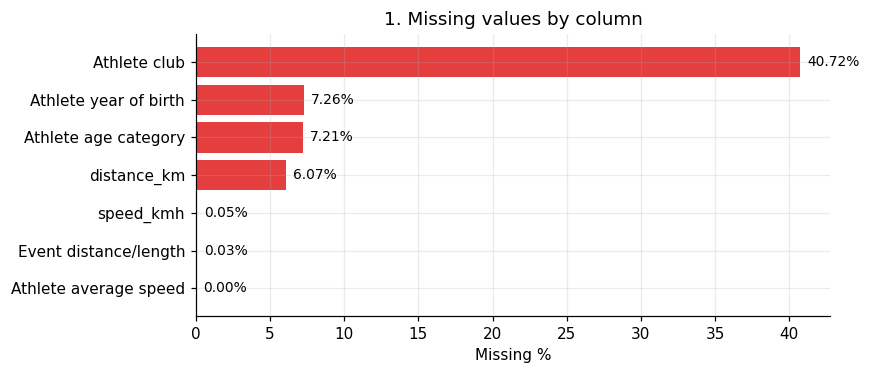

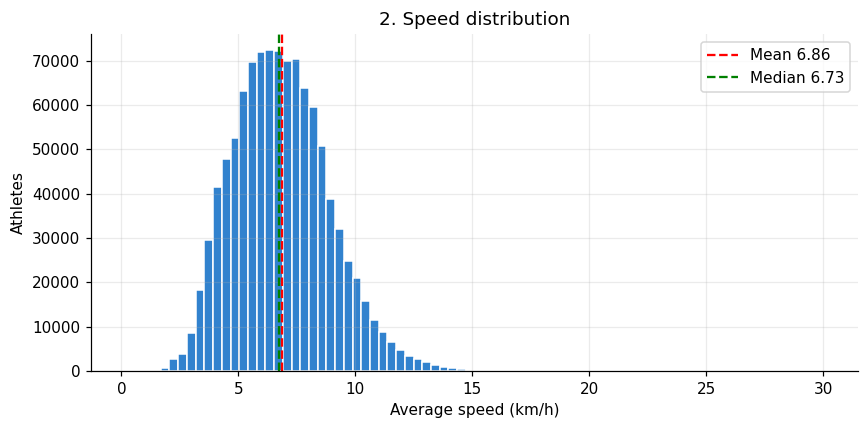

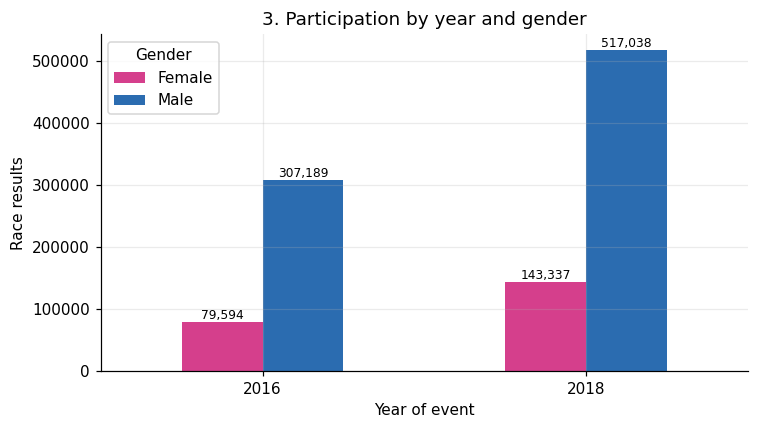

Female share (%): {2016: 20.58, 2018: 21.71}


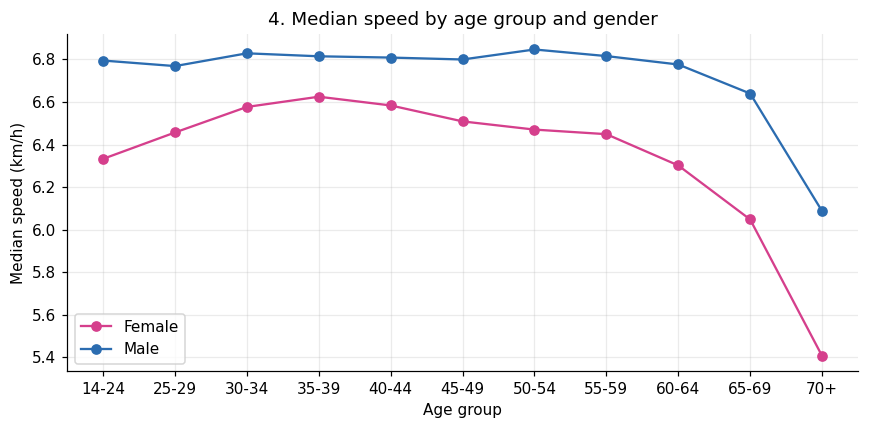

Median speed by gender: {'Female': 6.499, 'Male': 6.8}


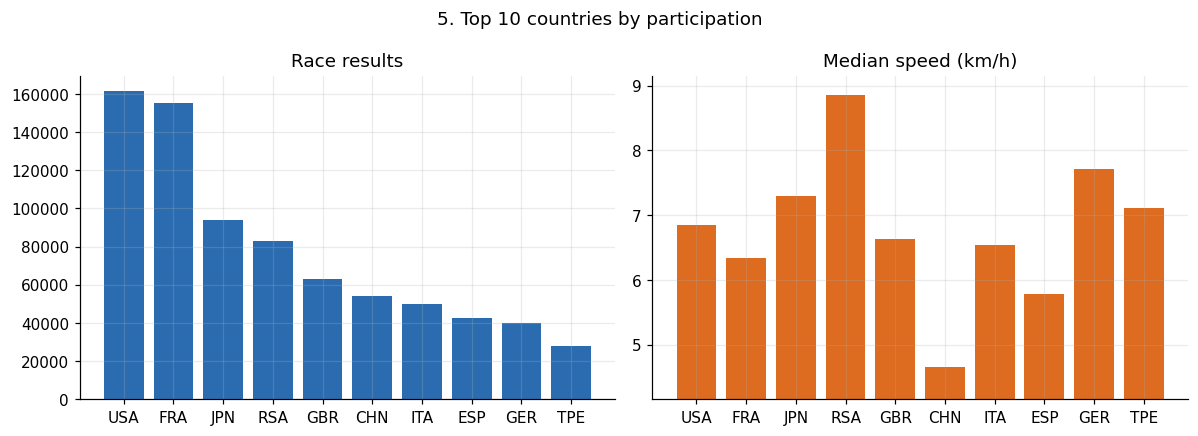

                   rows  median_speed
Athlete country                      
USA              161495          6.84
FRA              155228          6.34
JPN               93916          7.29
RSA               83119          8.86
GBR               62983          6.63
CHN               54106          4.65
ITA               50010          6.54
ESP               42743          5.78
GER               39786          7.72
TPE               27820          7.11


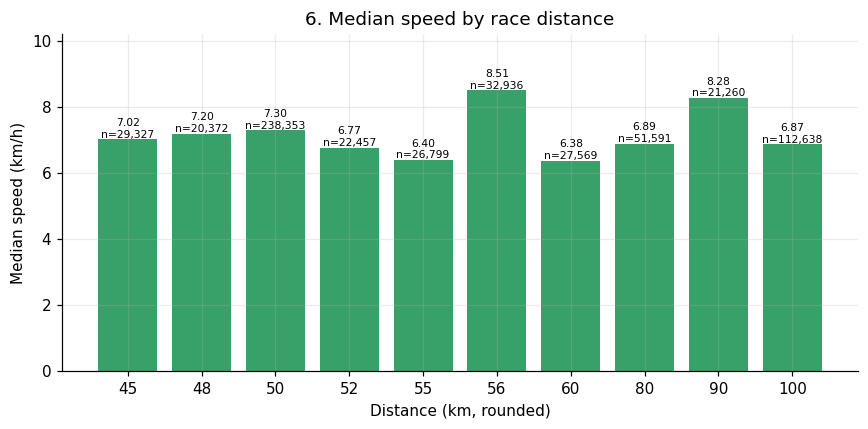

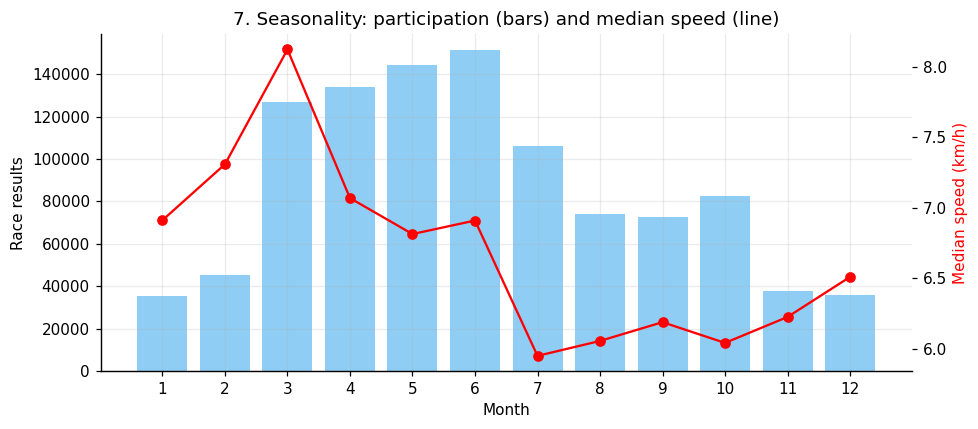

Busiest month: 6 | Fastest month: 3 | Slowest month: 7


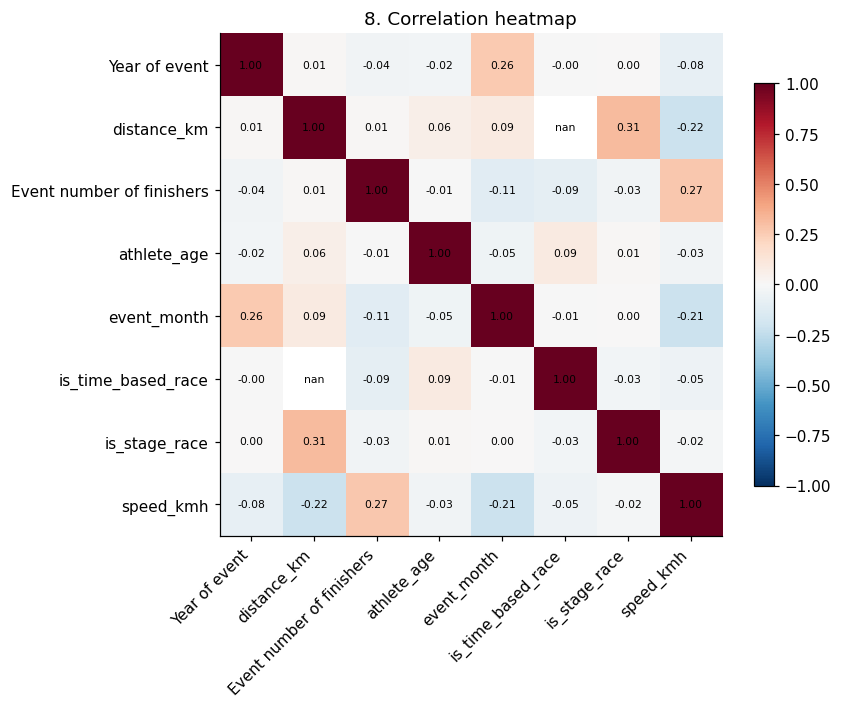


Correlation with speed:
distance_km                 -0.217
event_month                 -0.214
Year of event               -0.080
is_time_based_race          -0.050
athlete_age                 -0.034
is_stage_race               -0.021
Event number of finishers    0.266
Name: speed_kmh, dtype: float64

Charts saved in: /kaggle/working/charts


In [2]:
# ============================================================
# STEP 9 (STANDALONE): VISUALIZATION
# Runs on its own: no need to run Step 1-4 first.
# Part A rebuilds the cleaned data, Part B draws 8 charts.
# ============================================================

# ------------------------------------------------------------
# PART A: LOAD + CLEAN (same logic as Step 1-4)
# ------------------------------------------------------------
import os
import numpy as np
import pandas as pd

KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(PATH, low_memory=False)
raw_cols = list(df.columns)

def parse_distance_km(s):
    """'50km' -> 50 | '50mi' -> 80.47 | '100km/2Etappen' -> 100 | '24h' -> NaN (time-based)"""
    if pd.isna(s):
        return np.nan
    first = str(s).lower().replace(" ", "").split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)

TARGET = "speed_kmh"
NUMERIC_FEATURES = ["Year of event", "distance_km", "Event number of finishers",
                    "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]

data = df.copy()
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce").dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]
data = data.drop_duplicates(subset=raw_cols)
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
data.loc[bad_age, "athlete_age"] = np.nan
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
print("Cleaned data ready:", data.shape)

# ------------------------------------------------------------
# PART B: CHARTS
# ------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("charts", exist_ok=True)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(f"charts/{name}.png", bbox_inches="tight")
    plt.show()

plot = data.copy()                       # cleaned data from Step 4
plot["Gender"] = plot["Athlete gender"].map({"M": "Male", "F": "Female"})
COLORS = {"Male": "#2b6cb0", "Female": "#d53f8c"}

# ------------------------------------------------------------
# 1. MISSING VALUES (raw data)
# ------------------------------------------------------------
miss = (df.isnull().mean() * 100).sort_values()
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(miss.index, miss.values, color="#e53e3e")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlabel("Missing %"); ax.set_title("1. Missing values by column")
finish(fig, "01_missing_values")

# ------------------------------------------------------------
# 2. TARGET DISTRIBUTION
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(plot[TARGET], bins=80, color="#3182ce", edgecolor="white")
ax.axvline(plot[TARGET].mean(), color="red", ls="--", label=f"Mean {plot[TARGET].mean():.2f}")
ax.axvline(plot[TARGET].median(), color="green", ls="--", label=f"Median {plot[TARGET].median():.2f}")
ax.set_xlabel("Average speed (km/h)"); ax.set_ylabel("Athletes")
ax.set_title("2. Speed distribution"); ax.legend()
finish(fig, "02_speed_distribution")

# ------------------------------------------------------------
# 3. PARTICIPATION BY YEAR AND GENDER
# ------------------------------------------------------------
yg = plot.groupby(["Year of event", "Gender"]).size().unstack()
fig, ax = plt.subplots(figsize=(7, 4))
yg.plot(kind="bar", ax=ax, color=[COLORS[c] for c in yg.columns], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", fontsize=8)
ax.set_ylabel("Race results"); ax.set_title("3. Participation by year and gender")
finish(fig, "03_year_gender")
print("Female share (%):", (plot["Gender"].eq("Female").groupby(plot["Year of event"]).mean() * 100).round(2).to_dict())

# ------------------------------------------------------------
# 4. SPEED BY AGE GROUP AND GENDER
# ------------------------------------------------------------
plot["age_group"] = pd.cut(plot["athlete_age"], bins=[13, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 90],
                           labels=["14-24", "25-29", "30-34", "35-39", "40-44", "45-49",
                                   "50-54", "55-59", "60-64", "65-69", "70+"])
ag = plot.groupby(["age_group", "Gender"], observed=True)[TARGET].median().unstack()
fig, ax = plt.subplots(figsize=(8, 4))
for g in ag.columns:
    ax.plot(ag.index.astype(str), ag[g], marker="o", label=g, color=COLORS[g])
ax.set_xlabel("Age group"); ax.set_ylabel("Median speed (km/h)")
ax.set_title("4. Median speed by age group and gender"); ax.legend()
finish(fig, "04_age_gender_speed")
print("Median speed by gender:", plot.groupby("Gender")[TARGET].median().round(3).to_dict())

# ------------------------------------------------------------
# 5. TOP 10 COUNTRIES: participation + median speed
# ------------------------------------------------------------
top = plot["Athlete country"].value_counts().head(10).index
ct = plot[plot["Athlete country"].isin(top)].groupby("Athlete country").agg(
    rows=(TARGET, "size"), median_speed=(TARGET, "median")).loc[top]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(ct.index, ct["rows"], color="#2b6cb0"); axes[0].set_title("Race results")
axes[1].bar(ct.index, ct["median_speed"], color="#dd6b20"); axes[1].set_title("Median speed (km/h)")
axes[1].set_ylim(ct["median_speed"].min() - 0.5, ct["median_speed"].max() + 0.3)
fig.suptitle("5. Top 10 countries by participation")
finish(fig, "05_top_countries")
print(ct.round(2))

# ------------------------------------------------------------
# 6. DISTANCE vs SPEED (10 most common fixed distances)
# ------------------------------------------------------------
fixed = plot.dropna(subset=["distance_km"]).copy()
fixed["dist_round"] = fixed["distance_km"].round().astype(int)
common = fixed["dist_round"].value_counts().head(10).index
dd = fixed[fixed["dist_round"].isin(common)].groupby("dist_round").agg(
    rows=(TARGET, "size"), median_speed=(TARGET, "median")).sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dd.index.astype(str), dd["median_speed"], color="#38a169")
for i, (v, n) in enumerate(zip(dd["median_speed"], dd["rows"])):
    ax.text(i, v + 0.05, f"{v:.2f}\nn={n:,}", ha="center", fontsize=7)
ax.set_ylim(0, dd["median_speed"].max() * 1.2)
ax.set_xlabel("Distance (km, rounded)"); ax.set_ylabel("Median speed (km/h)")
ax.set_title("6. Median speed by race distance")
finish(fig, "06_distance_speed")

# ------------------------------------------------------------
# 7. MONTH: participation + speed
# ------------------------------------------------------------
mo = plot.groupby("event_month").agg(rows=(TARGET, "size"), median_speed=(TARGET, "median"))
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(mo.index, mo["rows"], color="#90cdf4"); ax1.set_ylabel("Race results")
ax1.set_xticks(range(1, 13)); ax1.set_xlabel("Month")
ax2 = ax1.twinx(); ax2.plot(mo.index, mo["median_speed"], color="red", marker="o")
ax2.set_ylabel("Median speed (km/h)", color="red"); ax2.grid(False)
ax1.set_title("7. Seasonality: participation (bars) and median speed (line)")
finish(fig, "07_monthly")
print("Busiest month:", int(mo["rows"].idxmax()), "| Fastest month:", int(mo["median_speed"].idxmax()),
      "| Slowest month:", int(mo["median_speed"].idxmin()))

# ------------------------------------------------------------
# 8. CORRELATION HEATMAP
# ------------------------------------------------------------
corr = plot[NUMERIC_FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.8); ax.set_title("8. Correlation heatmap")
finish(fig, "08_correlation")
print("\nCorrelation with speed:")
print(corr[TARGET].drop(TARGET).sort_values().round(3))

print("\nCharts saved in:", os.path.abspath("charts"))

In [3]:
# ============================================================
# STEP 10 (STANDALONE): CROSS VALIDATION
# Runs on its own: no need to run Step 1-9 first.
#
# Models  : Dummy (majority class) | Gaussian Naive Bayes | Logistic Regression
# CV types: 1) StratifiedKFold (5 folds)   2) GroupKFold by Athlete ID (5 folds)
# Target  : 3 speed classes (Slow / Medium / Fast), same as Step 7
# All imputation, encoding and scaling happen INSIDE each fold (Pipeline),
# so validation folds never influence the fill values or the scaler.
# ============================================================
import os
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# A. LOAD + CLEAN (same logic as Step 1-4)
# ------------------------------------------------------------
KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(PATH, low_memory=False)
raw_cols = list(df.columns)

def parse_distance_km(s):
    """'50km' -> 50 | '50mi' -> 80.47 | '100km/2Etappen' -> 100 | '24h' -> NaN (time-based)"""
    if pd.isna(s):
        return np.nan
    first = str(s).lower().replace(" ", "").split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)

data = df.copy()
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce").dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]
data = data.drop_duplicates(subset=raw_cols)
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
data.loc[bad_age, "athlete_age"] = np.nan
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
data["Athlete age category"] = data["Athlete age category"].str.strip().str.upper()
print("Cleaned data:", data.shape)

# ------------------------------------------------------------
# B. FEATURES / TARGET
# ------------------------------------------------------------
NUMERIC_FEATURES = ["Year of event", "distance_km", "Event number of finishers",
                    "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]
CATEGORICAL_FEATURES = ["Athlete country", "Athlete gender", "Athlete age category"]
X = data[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
groups = data["Athlete ID"]

# Speed -> 3 balanced classes (cut points = 33rd / 67th percentile of speed)
q1, q2 = data["speed_kmh"].quantile([1/3, 2/3])
y = pd.cut(data["speed_kmh"], bins=[-np.inf, q1, q2, np.inf], labels=["Slow", "Medium", "Fast"])
print(f"Classes: Slow <= {q1:.3f} < Medium <= {q2:.3f} < Fast")
print("Class share (%):", (y.value_counts(normalize=True) * 100).round(2).to_dict())

# ------------------------------------------------------------
# C. PIPELINES (preprocessing is re-fitted inside every fold)
# ------------------------------------------------------------
def make_preprocessor():
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                    ("scale", StandardScaler())])
    return ColumnTransformer([("num", num, NUMERIC_FEATURES), ("cat", cat, CATEGORICAL_FEATURES)])

models = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=300, random_state=42),
}

# ------------------------------------------------------------
# D. CROSS VALIDATION
# ------------------------------------------------------------
N_SPLITS = 5
cv_strategies = {
    "StratifiedKFold": (StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42), None),
    "GroupKFold (by Athlete ID)": (GroupKFold(n_splits=N_SPLITS), groups),
}

summary, fold_scores = [], {}
for cv_name, (cv, grp) in cv_strategies.items():
    for m_name, model in models.items():
        pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
        t0 = time.time()
        res = cross_validate(pipe, X, y, cv=cv, groups=grp,
                             scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"})
        fold_scores[(cv_name, m_name)] = res["test_accuracy"]
        summary.append({
            "CV": cv_name, "Model": m_name,
            "Accuracy mean": res["test_accuracy"].mean(), "Accuracy std": res["test_accuracy"].std(),
            "Macro F1 mean": res["test_f1_macro"].mean(), "Macro F1 std": res["test_f1_macro"].std(),
            "Time (s)": time.time() - t0,
        })
        print(f"Done: {cv_name:<27} | {m_name:<23} | {time.time() - t0:.1f}s")

summary = pd.DataFrame(summary).round(4)
print("\n--- Cross-validation results (5 folds) ---")
print(summary.to_string(index=False))

print("\n--- Accuracy per fold ---")
folds = pd.DataFrame({f"{c} | {m}": v for (c, m), v in fold_scores.items()},
                     index=[f"fold_{i+1}" for i in range(N_SPLITS)]).T.round(4)
print(folds.to_string())

# ------------------------------------------------------------
# E. DOES THE SAME ATHLETE LEAK ACROSS FOLDS?  (Stratified vs Group gap)
# ------------------------------------------------------------
print("\n--- Leakage check: Stratified minus Group (Macro F1) ---")
for m_name in models:
    s = summary[(summary["CV"] == "StratifiedKFold") & (summary["Model"] == m_name)]["Macro F1 mean"].iloc[0]
    g = summary[(summary["CV"] == "GroupKFold (by Athlete ID)") & (summary["Model"] == m_name)]["Macro F1 mean"].iloc[0]
    print(f"{m_name:<23}: Stratified {s:.4f} | Group {g:.4f} | gap {s - g:+.4f}")

athletes = data["Athlete ID"].nunique()
repeat = (data["Athlete ID"].value_counts() > 1).mean() * 100
print(f"\nUnique athletes: {athletes:,} | share with 2+ results: {repeat:.1f}%")

Cleaned data: (1047158, 19)
Classes: Slow <= 5.831 < Medium <= 7.655 < Fast
Class share (%): {'Slow': 33.34, 'Fast': 33.33, 'Medium': 33.33}
Done: StratifiedKFold             | Dummy (majority class)  | 19.4s
Done: StratifiedKFold             | Gaussian Naive Bayes    | 24.0s
Done: StratifiedKFold             | Logistic Regression     | 43.2s
Done: GroupKFold (by Athlete ID)  | Dummy (majority class)  | 19.9s
Done: GroupKFold (by Athlete ID)  | Gaussian Naive Bayes    | 24.7s
Done: GroupKFold (by Athlete ID)  | Logistic Regression     | 44.5s

--- Cross-validation results (5 folds) ---
                        CV                  Model  Accuracy mean  Accuracy std  Macro F1 mean  Macro F1 std  Time (s)
           StratifiedKFold Dummy (majority class)         0.3334        0.0000         0.1667        0.0000   19.3800
           StratifiedKFold   Gaussian Naive Bayes         0.4654        0.0011         0.4517        0.0012   23.9695
           StratifiedKFold    Logistic Regression    

Cleaned data: (1047158, 19)
Train: (837726, 10) | Test: (209432, 10)
Features going into RFECV (12): ['Year of event', 'distance_km', 'Event number of finishers', 'athlete_age', 'event_month', 'is_time_based_race', 'is_stage_race', 'missingindicator_distance_km', 'missingindicator_athlete_age', 'Athlete country', 'Athlete gender', 'Athlete age category']

RFECV finished in 30.5s on 199,999 rows

--- CV Macro F1 by number of features ---
 n_features  cv_macro_f1_mean  cv_macro_f1_std
          1            0.3436           0.0037
          2            0.4156           0.0021
          3            0.4494           0.0019
          4            0.4641           0.0018
          5            0.4676           0.0037
          6            0.4748           0.0024
          7            0.4747           0.0014
          8            0.4747           0.0014
          9            0.4774           0.0020
         10            0.4797           0.0012
         11            0.4798           0.

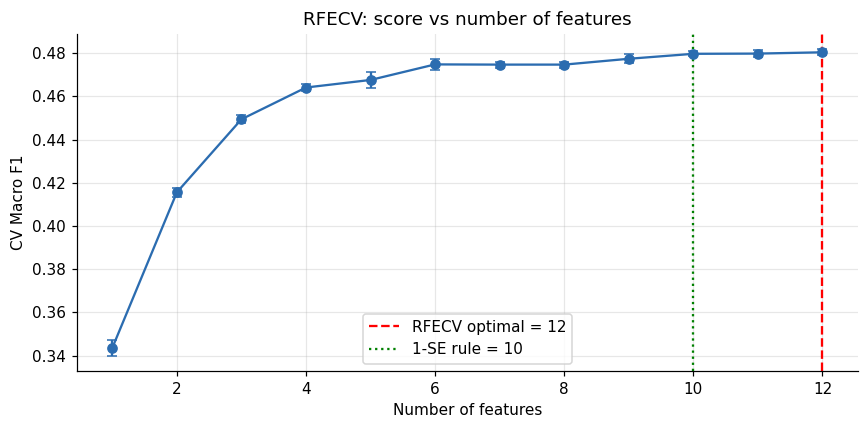


--- Test-set comparison ---
        Feature set  n_features  Accuracy  Macro F1  Fit time (s)
       All features          12    0.4827    0.4801        6.6183
RFECV selected (12)          12    0.4827    0.4801        6.5216
     1-SE rule (10)          10    0.4812    0.4787        5.6789


In [4]:
# ============================================================
# STEP 11 (STANDALONE): FEATURE SELECTION WITH RFECV
# Runs on its own: no need to run Step 1-10 first.
#
# RFECV = Recursive Feature Elimination with Cross-Validation.
# It trains a model, drops the weakest feature, repeats, and uses CV to find
# the number of features that gives the best score.
#
# Estimator : Logistic Regression (has coef_, needed by RFE; best model so far)
# Target    : 3 speed classes (Slow / Medium / Fast), same as Step 7
# Speed     : RFECV runs on a 200,000-row stratified sample of TRAIN;
#             the final comparison uses the full train and the untouched test set.
# ============================================================
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE, RFECV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

# ------------------------------------------------------------
# A. LOAD + CLEAN (same logic as Step 1-4)
# ------------------------------------------------------------
KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(PATH, low_memory=False)
raw_cols = list(df.columns)

def parse_distance_km(s):
    """'50km' -> 50 | '50mi' -> 80.47 | '100km/2Etappen' -> 100 | '24h' -> NaN (time-based)"""
    if pd.isna(s):
        return np.nan
    first = str(s).lower().replace(" ", "").split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)

data = df.copy()
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce").dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]
data = data.drop_duplicates(subset=raw_cols)
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
data.loc[bad_age, "athlete_age"] = np.nan
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
data["Athlete age category"] = data["Athlete age category"].str.strip().str.upper()
print("Cleaned data:", data.shape)

# ------------------------------------------------------------
# B. FEATURES / TARGET + TRAIN-TEST SPLIT
# ------------------------------------------------------------
NUMERIC_FEATURES = ["Year of event", "distance_km", "Event number of finishers",
                    "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]
CATEGORICAL_FEATURES = ["Athlete country", "Athlete gender", "Athlete age category"]
X = data[NUMERIC_FEATURES + CATEGORICAL_FEATURES]

# Speed -> 3 classes. Cut points come from the TRAIN part only.
X_train, X_test, spd_train, spd_test = train_test_split(X, data["speed_kmh"], test_size=0.2, random_state=42)
q1, q2 = spd_train.quantile([1/3, 2/3])
labels = ["Slow", "Medium", "Fast"]
y_train = pd.cut(spd_train, bins=[-np.inf, q1, q2, np.inf], labels=labels)
y_test = pd.cut(spd_test, bins=[-np.inf, q1, q2, np.inf], labels=labels)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# ------------------------------------------------------------
# C. PREPROCESSING (fit on TRAIN only)
# ------------------------------------------------------------
num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                ("scale", StandardScaler())])
cat = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                ("scale", StandardScaler())])
prep = ColumnTransformer([("num", num, NUMERIC_FEATURES), ("cat", cat, CATEGORICAL_FEATURES)],
                         verbose_feature_names_out=False)

Xtr = prep.fit_transform(X_train)
Xte = prep.transform(X_test)
feature_names = np.array(prep.get_feature_names_out())
print(f"Features going into RFECV ({len(feature_names)}):", list(feature_names))

# ------------------------------------------------------------
# D. RFECV (on a stratified 200k sample of train, for speed)
# ------------------------------------------------------------
SAMPLE = 200_000
idx = (pd.Series(np.arange(len(y_train)))
       .groupby(y_train.values, group_keys=False)
       .apply(lambda s: s.sample(int(SAMPLE * len(s) / len(y_train)), random_state=42)).values)

rfecv = RFECV(
    estimator=LogisticRegression(max_iter=300, random_state=42),
    step=1,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro",
    min_features_to_select=1,
    n_jobs=-1,
)
t0 = time.time()
rfecv.fit(Xtr[idx], y_train.iloc[idx])
print(f"\nRFECV finished in {time.time() - t0:.1f}s on {len(idx):,} rows")

# ------------------------------------------------------------
# E. RESULTS
# ------------------------------------------------------------
scores = pd.DataFrame({
    "n_features": np.arange(1, len(feature_names) + 1),
    "cv_macro_f1_mean": rfecv.cv_results_["mean_test_score"],
    "cv_macro_f1_std": rfecv.cv_results_["std_test_score"],
}).round(4)
print("\n--- CV Macro F1 by number of features ---")
print(scores.to_string(index=False))

ranking = (pd.DataFrame({"feature": feature_names, "rank": rfecv.ranking_, "selected": rfecv.support_})
           .sort_values("rank").reset_index(drop=True))
print(f"\nOptimal number of features: {rfecv.n_features_} of {len(feature_names)}")
print("\n--- Feature ranking (1 = kept until the end) ---")
print(ranking.to_string(index=False))

selected = feature_names[rfecv.support_]
dropped = feature_names[~rfecv.support_]
print("\nSelected:", list(selected))
print("Dropped :", list(dropped))

# ---- Full elimination order (RFECV keeps everything here, so RFE shows which features are weakest) ----
rfe = RFE(LogisticRegression(max_iter=300, random_state=42), n_features_to_select=1, step=1)
rfe.fit(Xtr[idx], y_train.iloc[idx])
order = (pd.DataFrame({"feature": feature_names, "importance_rank": rfe.ranking_})
         .sort_values("importance_rank").reset_index(drop=True))
print("\n--- Importance order (1 = strongest, last = eliminated first) ---")
print(order.to_string(index=False))

# ---- Simpler alternative: fewest features within 1 std of the best CV score ("1-SE rule") ----
best_row = scores.loc[scores["cv_macro_f1_mean"].idxmax()]
threshold = best_row["cv_macro_f1_mean"] - best_row["cv_macro_f1_std"]
n_1se = int(scores.loc[scores["cv_macro_f1_mean"] >= threshold, "n_features"].min())
cols_1se = np.where(rfe.ranking_ <= n_1se)[0]
print(f"\n1-SE rule: best CV F1 = {best_row['cv_macro_f1_mean']:.4f} (std {best_row['cv_macro_f1_std']:.4f}); "
      f"smallest set within 1 std = {n_1se} features")
print("1-SE features:", list(feature_names[cols_1se]))

# Chart: CV score vs number of features
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(scores["n_features"], scores["cv_macro_f1_mean"], yerr=scores["cv_macro_f1_std"],
            marker="o", color="#2b6cb0", capsize=3)
ax.axvline(rfecv.n_features_, color="red", ls="--", label=f"RFECV optimal = {rfecv.n_features_}")
ax.axvline(n_1se, color="green", ls=":", label=f"1-SE rule = {n_1se}")
ax.set_xlabel("Number of features"); ax.set_ylabel("CV Macro F1")
ax.set_title("RFECV: score vs number of features"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("rfecv_curve.png", dpi=120); plt.show()

# ------------------------------------------------------------
# F. FINAL CHECK: all features vs selected features (full train -> untouched test)
# ------------------------------------------------------------
rows = []
for name, cols in [("All features", np.arange(len(feature_names))),
                   (f"RFECV selected ({rfecv.n_features_})", np.where(rfecv.support_)[0]),
                   (f"1-SE rule ({n_1se})", cols_1se)]:
    t0 = time.time()
    model = LogisticRegression(max_iter=300, random_state=42).fit(Xtr[:, cols], y_train)
    pred = model.predict(Xte[:, cols])
    rows.append({"Feature set": name, "n_features": len(cols),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Macro F1": f1_score(y_test, pred, average="macro"),
                 "Fit time (s)": time.time() - t0})
print("\n--- Test-set comparison ---")
print(pd.DataFrame(rows).round(4).to_string(index=False))

Cleaned data: (1047158, 19)
Classes: Slow <= 5.831 < Medium <= 7.654 < Fast

Model test accuracy: 0.4827 | Macro F1: 0.4801
Model class order: ['Fast', 'Medium', 'Slow']

=== Correct Slow case ===
Race result #444412 | M | age 39 | FRA | distance 204 km | finishers 115 | month 9
Actual: Slow | Predicted: Slow | Probabilities: Fast 2.8%, Medium 17.1%, Slow 80.2%
                          Feature condition  Weight toward Slow
                        distance_km > 89.00              0.2076
                      is_stage_race <= 0.00              0.1834
                         event_month > 8.00              0.1108
                           Athlete gender=M             -0.0806
                 is_time_based_race <= 0.00             -0.0665
98.00 < Event number of finishers <= 229.00              0.0619
                        Athlete country=FRA              0.0549
               distance_was_missing <= 0.00             -0.0380
LIME local fit R2: 0.475


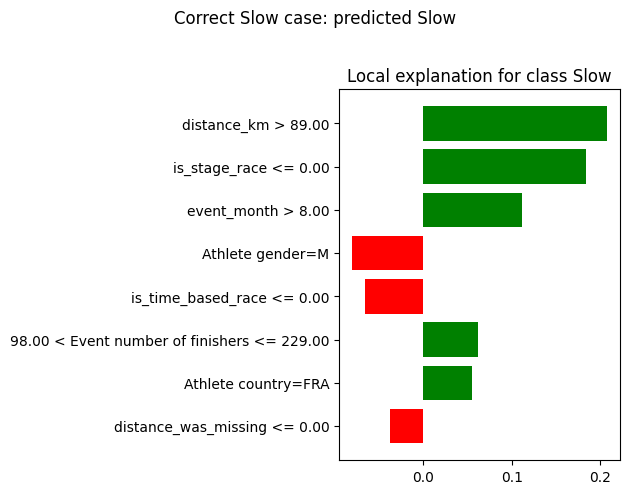


=== Correct Medium case ===
Race result #482787 | M | age 62 | USA | distance 80 km | finishers 42 | month 8
Actual: Medium | Predicted: Medium | Probabilities: Fast 24.5%, Medium 47.4%, Slow 28.1%
                 Feature condition  Weight toward Medium
        is_time_based_race <= 0.00                0.0779
      distance_was_missing <= 0.00                0.0739
           age_was_missing <= 0.00               -0.0599
               Athlete country=USA                0.0565
Event number of finishers <= 98.00                0.0418
               athlete_age > 48.00                0.0334
             is_stage_race <= 0.00                0.0152
      60.00 < distance_km <= 89.00                0.0110
LIME local fit R2: 0.242


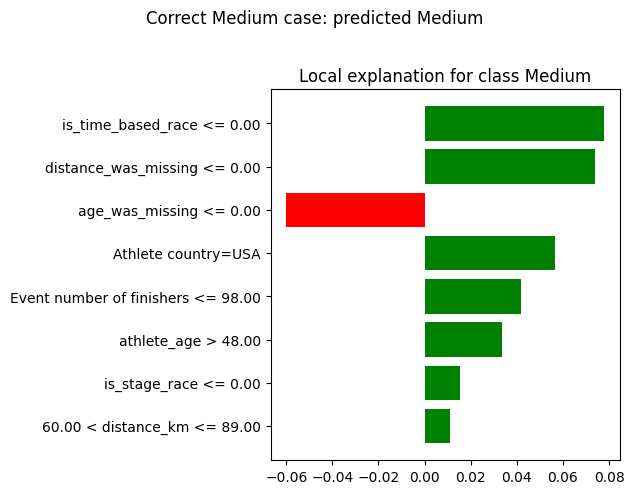


=== Correct Fast case ===
Race result #223992 | M | age 43 | RSA | distance 90 km | finishers 16484 | month 6
Actual: Fast | Predicted: Fast | Probabilities: Fast 94.5%, Medium 4.4%, Slow 1.1%
                 Feature condition  Weight toward Fast
Event number of finishers > 598.00              0.3020
               distance_km > 89.00             -0.1927
             is_stage_race <= 0.00             -0.1895
                  Athlete gender=M              0.0835
           age_was_missing <= 0.00              0.0375
      distance_was_missing <= 0.00             -0.0351
               Athlete country=RSA              0.0319
                Year of event=2018             -0.0187
LIME local fit R2: 0.673


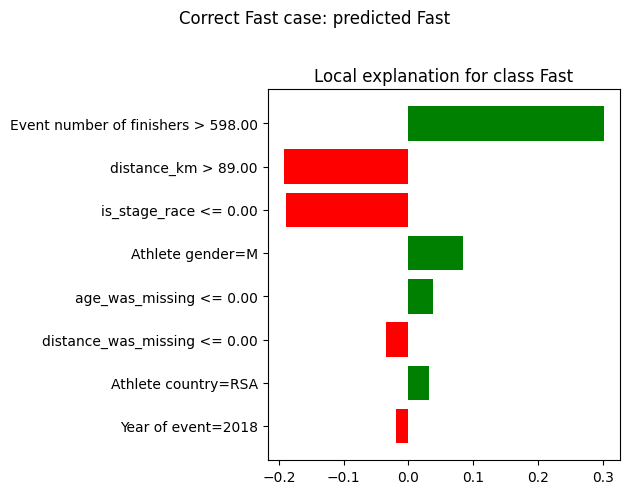


=== Confident wrong case ===
Race result #600406 | F | age 35 | BRU | distance 60 km | finishers 96 | month 12
Actual: Fast | Predicted: Slow | Probabilities: Fast 10.8%, Medium 25.5%, Slow 63.7%
                 Feature condition  Weight toward Slow
               Athlete country=BRU              0.1621
             is_stage_race <= 0.00              0.1542
                  Athlete gender=F              0.1004
                event_month > 8.00              0.0992
      50.00 < distance_km <= 60.00             -0.0864
        is_time_based_race <= 0.00             -0.0742
Event number of finishers <= 98.00              0.0710
      distance_was_missing <= 0.00             -0.0560
LIME local fit R2: 0.229


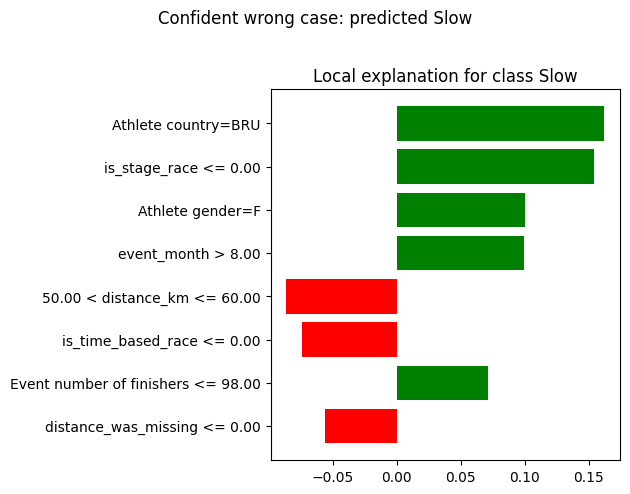


Global LIME on 150 rows took 2.4s

--- Global LIME importance (mean |weight|, 150 test rows) ---
is_stage_race                0.1372
Event number of finishers    0.1124
distance_km                  0.0835
Athlete gender               0.0663
is_time_based_race           0.0517
distance_was_missing         0.0510
event_month                  0.0505
Athlete country              0.0450
age_was_missing              0.0344
Year of event                0.0148
athlete_age                  0.0134
Athlete age category         0.0096


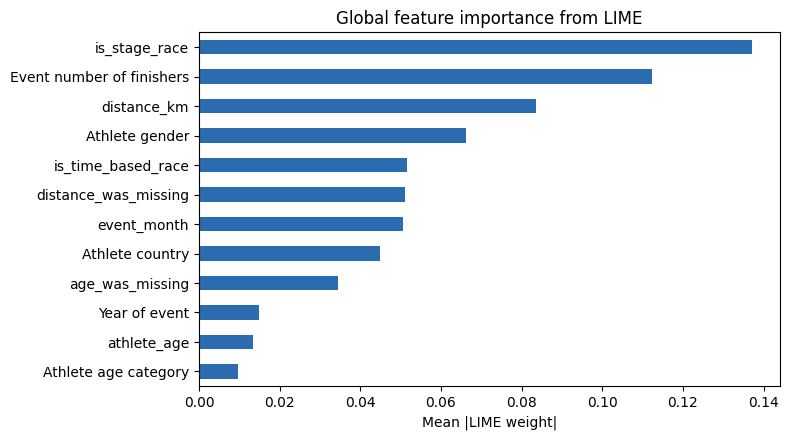


Files saved in: /kaggle/working/lime_output


In [1]:
# ============================================================
# STEP 12 (STANDALONE): EXPLAINABLE AI WITH LIME
# Runs on its own: no need to run Step 1-11 first.
#
# Model   : StandardScaler + Logistic Regression (best model so far)
# Target  : 3 speed classes (Slow / Medium / Fast), same as Step 7
# LIME    : explains WHY the model predicted a class for ONE athlete's race result
#           (local explanation), then averages 150 explanations for a global view.
# Kaggle  : if "lime" is missing the cell installs it automatically.
# ============================================================
import os
import sys
import time
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
    from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
os.makedirs("lime_output", exist_ok=True)

# ------------------------------------------------------------
# A. LOAD + CLEAN (same logic as Step 1-4)
# ------------------------------------------------------------
KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(PATH, low_memory=False)
raw_cols = list(df.columns)

def parse_distance_km(s):
    """'50km' -> 50 | '50mi' -> 80.47 | '100km/2Etappen' -> 100 | '24h' -> NaN (time-based)"""
    if pd.isna(s):
        return np.nan
    first = str(s).lower().replace(" ", "").split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)

data = df.copy()
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce").dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]
data = data.drop_duplicates(subset=raw_cols)
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
data.loc[bad_age, "athlete_age"] = np.nan
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
data["Athlete age category"] = data["Athlete age category"].str.strip().str.upper()
print("Cleaned data:", data.shape)

# ------------------------------------------------------------
# B. FEATURES, SPLIT, CLASSES
# ------------------------------------------------------------
# "Year of event" is treated as a CATEGORY: it only has a few distinct values, and LIME's
# automatic binning of such a feature exaggerates its weight (see the check at the end).
NUMERIC = ["distance_km", "Event number of finishers",
           "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]
CATEGORICAL = ["Year of event", "Athlete country", "Athlete gender", "Athlete age category"]
X = data[NUMERIC + CATEGORICAL].copy()
X["Year of event"] = X["Year of event"].astype(int).astype(str)

X_train, X_test, spd_train, spd_test = train_test_split(X, data["speed_kmh"], test_size=0.2, random_state=42)
q1, q2 = spd_train.quantile([1/3, 2/3])
class_names = ["Slow", "Medium", "Fast"]
to_class = lambda s: pd.cut(s, bins=[-np.inf, q1, q2, np.inf], labels=class_names).astype(str)
y_train, y_test = to_class(spd_train).values, to_class(spd_test).values   # plain arrays (positional)
print(f"Classes: Slow <= {q1:.3f} < Medium <= {q2:.3f} < Fast")

# ------------------------------------------------------------
# C. PREPARE DATA FOR LIME (readable numeric array, fit on TRAIN only)
#    Numeric  : median imputation + 2 missing-flag columns
#    Category : "Unknown" fill + integer codes (LIME needs integer codes + names)
# ------------------------------------------------------------
num_imp = SimpleImputer(strategy="median").fit(X_train[NUMERIC])
cat_cats = [sorted(set(X_train[c].fillna("Unknown")) | {"Unknown"}) for c in CATEGORICAL]
cat_enc = OrdinalEncoder(categories=cat_cats, handle_unknown="use_encoded_value", unknown_value=-1).fit(
    X_train[CATEGORICAL].fillna("Unknown"))

def prepare(Xdf):
    num = pd.DataFrame(num_imp.transform(Xdf[NUMERIC]), columns=NUMERIC, index=Xdf.index)
    flags = pd.DataFrame({"age_was_missing": Xdf["athlete_age"].isnull().astype(int),
                          "distance_was_missing": Xdf["distance_km"].isnull().astype(int)}, index=Xdf.index)
    codes = cat_enc.transform(Xdf[CATEGORICAL].fillna("Unknown"))
    codes = np.where(codes == -1, [c.index("Unknown") for c in cat_cats], codes)   # unseen -> Unknown
    cat = pd.DataFrame(codes, columns=CATEGORICAL, index=Xdf.index)
    return pd.concat([num, flags, cat], axis=1)

Ptr, Pte = prepare(X_train), prepare(X_test)
feature_names = list(Ptr.columns)
cat_idx = [feature_names.index(c) for c in CATEGORICAL]
categorical_names = {feature_names.index(c): cat_cats[i] for i, c in enumerate(CATEGORICAL)}

# ------------------------------------------------------------
# D. TRAIN MODEL
# ------------------------------------------------------------
model = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=300, random_state=42))])
model.fit(Ptr.values, y_train)
pred_test = model.predict(Pte.values)
print(f"\nModel test accuracy: {accuracy_score(y_test, pred_test):.4f} | "
      f"Macro F1: {f1_score(y_test, pred_test, average='macro'):.4f}")
classes = list(model.named_steps["lr"].classes_)        # alphabetical: Fast, Medium, Slow
print("Model class order:", classes)

# ------------------------------------------------------------
# E. LIME EXPLAINER
# ------------------------------------------------------------
explainer = LimeTabularExplainer(
    training_data=Ptr.sample(50_000, random_state=42).values,
    feature_names=feature_names,
    class_names=classes,
    categorical_features=cat_idx,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42,
)

def describe(i):
    """Readable profile of one test row."""
    r = X_test.iloc[i]
    return (f"Race result #{X_test.index[i]} | {r['Athlete gender']} | age {r['athlete_age']:.0f} | {r['Athlete country']} | "
            f"distance {r['distance_km']:.0f} km | finishers {r['Event number of finishers']:.0f} | month {r['event_month']:.0f}")

def explain_one(i, title, num_features=8, num_samples=3000):
    row = Pte.iloc[i].values
    proba = model.predict_proba(row.reshape(1, -1))[0]
    pred = classes[int(np.argmax(proba))]
    exp = explainer.explain_instance(row, model.predict_proba, num_features=num_features,
                                     num_samples=num_samples, labels=[int(np.argmax(proba))])
    print(f"\n=== {title} ===")
    print(describe(i))
    print(f"Actual: {y_test[i]} | Predicted: {pred} | Probabilities: " +
          ", ".join(f"{c} {p:.1%}" for c, p in zip(classes, proba)))
    table = pd.DataFrame(exp.as_list(label=int(np.argmax(proba))), columns=["Feature condition", f"Weight toward {pred}"]).round(4)
    print(table.to_string(index=False))
    print(f"LIME local fit R2: {exp.score:.3f}")
    name = title.lower().replace(" ", "_")
    exp.save_to_file(f"lime_output/{name}.html")
    fig = exp.as_pyplot_figure(label=int(np.argmax(proba)))
    fig.suptitle(f"{title}: predicted {pred}", y=1.02)
    fig.tight_layout(); fig.savefig(f"lime_output/{name}.png", dpi=120, bbox_inches="tight"); plt.show()

# ------------------------------------------------------------
# F. LOCAL EXPLANATIONS: 1 confident correct case per class + 1 wrong case
# ------------------------------------------------------------
proba_test = model.predict_proba(Pte.values)
conf = proba_test.max(axis=1)
y_arr, pred_arr = np.array(y_test), np.array(pred_test)
rng = np.random.RandomState(42)

def pick_confident(mask, top_share=0.05):
    """Random row among the top 5% most confident predictions inside `mask`."""
    idx = np.where(mask)[0]
    cutoff = np.quantile(conf[idx], 1 - top_share)
    return int(rng.choice(idx[conf[idx] >= cutoff]))

for cls in class_names:
    explain_one(pick_confident((y_arr == cls) & (pred_arr == cls)), f"Correct {cls} case")

explain_one(pick_confident(y_arr != pred_arr), "Confident wrong case")

# ------------------------------------------------------------
# G. GLOBAL VIEW: average |LIME weight| over 150 random test rows
# ------------------------------------------------------------
t0 = time.time()
sample_idx = rng.choice(len(Pte), 150, replace=False)
weights = {f: [] for f in feature_names}
for i in sample_idx:
    row = Pte.iloc[i].values
    lbl = int(np.argmax(model.predict_proba(row.reshape(1, -1))[0]))
    exp = explainer.explain_instance(row, model.predict_proba, num_features=len(feature_names),
                                     num_samples=2000, labels=[lbl])
    used = dict(exp.as_map()[lbl])
    for j, f in enumerate(feature_names):
        weights[f].append(abs(used.get(j, 0.0)))
print(f"\nGlobal LIME on 150 rows took {time.time() - t0:.1f}s")

global_imp = (pd.Series({f: np.mean(v) for f, v in weights.items()})
              .sort_values(ascending=False).rename("mean_abs_lime_weight").round(4))
print("\n--- Global LIME importance (mean |weight|, 150 test rows) ---")
print(global_imp.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
global_imp.sort_values().plot(kind="barh", color="#2b6cb0", ax=ax)
ax.set_xlabel("Mean |LIME weight|"); ax.set_title("Global feature importance from LIME")
fig.tight_layout(); fig.savefig("lime_output/global_importance.png", dpi=120); plt.show()
print("\nFiles saved in:", os.path.abspath("lime_output"))

Cleaned data: (1047158, 19)
Train 628,294 | Calibration 209,432 | Test 209,432
Classes: Slow <= 5.830 < Medium <= 7.654 < Fast

Test accuracy: 0.4825
Fitted temperature T = 1.010  (T > 1 = model was over-confident, T < 1 = under-confident)

--- Calibration (test set) ---
                           ECE (lower = better)   Brier  Log loss  Mean confidence  Accuracy
Before calibration                       0.0153  0.6005     0.999           0.4743    0.4825
After temperature scaling                0.0159  0.6005     0.999           0.4732    0.4825

--- Uncertainty measures (test set) ---
                         mean  median
Confidence (max prob)  0.4732  0.4314
Normalised entropy     0.9092  0.9660
Margin (top1 - top2)   0.1549  0.0871

--- Accuracy by confidence band ---
              rows  share_pct  accuracy  mean_conf
(0.0, 0.4]   60195    28.7420    0.3783     0.3737
(0.4, 0.5]  100945    48.1994    0.4508     0.4400
(0.5, 0.6]   24573    11.7332    0.5553     0.5408
(0.6, 0.7]    7

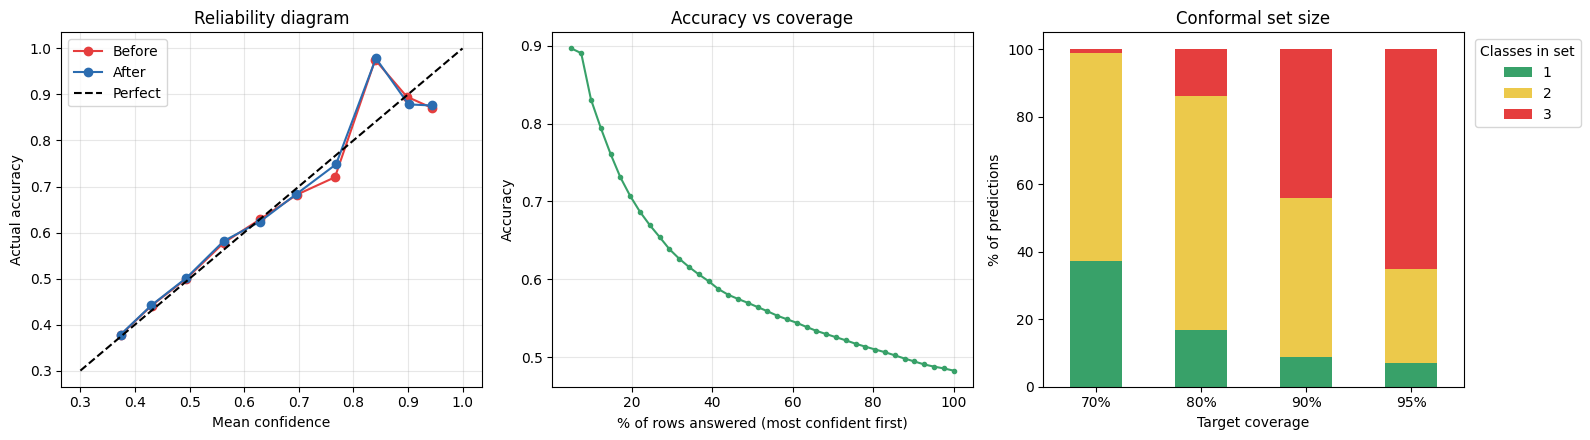


Chart saved: /kaggle/working/uq_output/uncertainty_charts.png


In [2]:
# ============================================================
# STEP 13 (STANDALONE): UNCERTAINTY QUANTIFICATION
# Runs on its own: no need to run Step 1-12 first.
#
# Model  : Logistic Regression (3 speed classes: Slow / Medium / Fast)
# Split  : 60% train | 20% calibration | 20% test   (calibration data is never used for training)
# Methods:
#   1) Predictive uncertainty : confidence, entropy, margin
#   2) Calibration            : ECE, Brier, log loss, before vs after temperature scaling
#   3) Selective prediction   : accuracy when the model only answers its most confident cases
#   4) Conformal prediction   : prediction SETS with a statistical coverage guarantee
#   5) Bootstrap              : 95% confidence intervals for accuracy and Macro F1
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
os.makedirs("uq_output", exist_ok=True)

# ------------------------------------------------------------
# A. LOAD + CLEAN (same logic as Step 1-4)
# ------------------------------------------------------------
KAGGLE_PATH = "/kaggle/input/datasets/fahim173/the-big-dataset-of-ultra-marathon-running/TWO_CENTURIES_OF_UM_RACES.csv"
LOCAL_PATH = "/mnt/user-data/uploads/TWO_CENTURIES_OF_UM_RACES.csv"
PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(PATH, low_memory=False)
raw_cols = list(df.columns)

def parse_distance_km(s):
    """'50km' -> 50 | '50mi' -> 80.47 | '100km/2Etappen' -> 100 | '24h' -> NaN (time-based)"""
    if pd.isna(s):
        return np.nan
    first = str(s).lower().replace(" ", "").split("/")[0]
    num = pd.Series([first]).str.extract(r"([0-9]+(?:[.,][0-9]+)?)")[0].iloc[0]
    if pd.isna(num):
        return np.nan
    num = float(str(num).replace(",", "."))
    if first.endswith("mi") or first.endswith("mile"):
        return num * 1.609344
    if "km" in first or first.endswith("k"):
        return num
    return np.nan

df["speed_kmh"] = pd.to_numeric(df["Athlete average speed"], errors="coerce")
df["distance_km"] = df["Event distance/length"].apply(parse_distance_km)

data = df.copy()
data["athlete_age"] = data["Year of event"] - data["Athlete year of birth"]
data["event_month"] = pd.to_datetime(
    data["Event dates"].str.extract(r"(\d{2}\.\d{4})$")[0], format="%m.%Y", errors="coerce").dt.month
data["is_time_based_race"] = data["distance_km"].isnull().astype(int)
data["is_stage_race"] = data["Event distance/length"].fillna("").str.contains(
    "Etappen|stages", case=False).astype(int)

data = data[data["speed_kmh"].notnull() & (data["speed_kmh"] > 0) & (data["speed_kmh"] <= 30)]
data = data[data["Athlete gender"].isin(["M", "F"])]
data = data.drop_duplicates(subset=raw_cols)
bad_age = (data["athlete_age"] < 14) | (data["athlete_age"] > 90)
data.loc[bad_age, "athlete_age"] = np.nan
data["Athlete country"] = data["Athlete country"].str.strip().str.upper()
data["Athlete age category"] = data["Athlete age category"].str.strip().str.upper()
print("Cleaned data:", data.shape)

# ------------------------------------------------------------
# B. FEATURES, 60/20/20 SPLIT, TARGET CLASSES
# ------------------------------------------------------------
NUMERIC = ["Year of event", "distance_km", "Event number of finishers",
           "athlete_age", "event_month", "is_time_based_race", "is_stage_race"]
CATEGORICAL = ["Athlete country", "Athlete gender", "Athlete age category"]
X = data[NUMERIC + CATEGORICAL]

X_train, X_tmp, s_train, s_tmp = train_test_split(X, data["speed_kmh"], test_size=0.4, random_state=42)
X_cal, X_test, s_cal, s_test = train_test_split(X_tmp, s_tmp, test_size=0.5, random_state=42)

class_names = ["Slow", "Medium", "Fast"]                       # ordered by speed
q1, q2 = s_train.quantile([1/3, 2/3])
to_code = lambda s: pd.cut(s, bins=[-np.inf, q1, q2, np.inf], labels=[0, 1, 2]).astype(int).values
y_train, y_cal, y_test = to_code(s_train), to_code(s_cal), to_code(s_test)
print(f"Train {len(X_train):,} | Calibration {len(X_cal):,} | Test {len(X_test):,}")
print(f"Classes: Slow <= {q1:.3f} < Medium <= {q2:.3f} < Fast")

# ------------------------------------------------------------
# C. MODEL
# ------------------------------------------------------------
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                      ("scale", StandardScaler())]), CATEGORICAL),
])
model = Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=300, random_state=42))])
model.fit(X_train, y_train)

logit_cal, logit_test = model.decision_function(X_cal), model.decision_function(X_test)
p_test_raw = softmax(logit_test, axis=1)
pred_test = p_test_raw.argmax(axis=1)
print(f"\nTest accuracy: {(pred_test == y_test).mean():.4f}")

# ------------------------------------------------------------
# D. CALIBRATION: temperature scaling fitted on the CALIBRATION set
# ------------------------------------------------------------
def nll(T, logits, y):
    return -(logits[np.arange(len(y)), y] / T - logsumexp(logits / T, axis=1)).mean()

T = minimize_scalar(lambda t: nll(t, logit_cal, y_cal), bounds=(0.05, 20), method="bounded").x
p_test_cal = softmax(logit_test / T, axis=1)
print(f"Fitted temperature T = {T:.3f}  (T > 1 = model was over-confident, T < 1 = under-confident)")

def ece_score(p, y, bins=15):
    conf, correct = p.max(axis=1), (p.argmax(axis=1) == y)
    edges = np.linspace(1/3, 1, bins + 1)                      # top-label confidence is >= 1/3 for 3 classes
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return sum(abs(correct[idx == b].mean() - conf[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

def brier(p, y):
    return ((p - np.eye(3)[y]) ** 2).sum(axis=1).mean()

def logloss(p, y):
    return -np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean()

calib = pd.DataFrame({
    "ECE (lower = better)": [ece_score(p_test_raw, y_test), ece_score(p_test_cal, y_test)],
    "Brier": [brier(p_test_raw, y_test), brier(p_test_cal, y_test)],
    "Log loss": [logloss(p_test_raw, y_test), logloss(p_test_cal, y_test)],
    "Mean confidence": [p_test_raw.max(1).mean(), p_test_cal.max(1).mean()],
    "Accuracy": [(p_test_raw.argmax(1) == y_test).mean()] * 2,
}, index=["Before calibration", "After temperature scaling"]).round(4)
print("\n--- Calibration (test set) ---")
print(calib.to_string())

# ------------------------------------------------------------
# E. PREDICTIVE UNCERTAINTY + SELECTIVE PREDICTION (using calibrated probabilities)
# ------------------------------------------------------------
P = p_test_cal
confidence = P.max(axis=1)
entropy = -(P * np.log(np.clip(P, 1e-12, 1))).sum(axis=1) / np.log(3)      # 0 = sure, 1 = fully unsure
top2 = np.sort(P, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]
correct = (P.argmax(axis=1) == y_test)

print("\n--- Uncertainty measures (test set) ---")
print(pd.DataFrame({"mean": [confidence.mean(), entropy.mean(), margin.mean()],
                    "median": [np.median(confidence), np.median(entropy), np.median(margin)]},
                   index=["Confidence (max prob)", "Normalised entropy", "Margin (top1 - top2)"]).round(4))

bins = pd.cut(confidence, [0, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0])
by_conf = pd.DataFrame({"correct": correct, "conf": confidence}).groupby(bins, observed=True).agg(
    rows=("correct", "size"), share_pct=("correct", lambda s: len(s) / len(correct) * 100),
    accuracy=("correct", "mean"), mean_conf=("conf", "mean")).round(4)
print("\n--- Accuracy by confidence band ---")
print(by_conf)

order = np.argsort(-confidence)
rows = []
for keep in [1.0, 0.8, 0.6, 0.4, 0.2, 0.1]:
    k = int(len(order) * keep)
    rows.append({"Answer only top % confident": f"{keep:.0%}", "Rows answered": k,
                 "Accuracy": correct[order[:k]].mean(), "Min confidence used": confidence[order[k - 1]]})
selective = pd.DataFrame(rows).round(4)
print("\n--- Selective prediction ---")
print(selective.to_string(index=False))

# ------------------------------------------------------------
# F. CONFORMAL PREDICTION (split conformal, calibration set)
#    Prediction SET = all classes with probability >= 1 - qhat.
#    Guarantee: the true class is inside the set at least (1 - alpha) of the time.
# ------------------------------------------------------------
P_cal = softmax(logit_cal / T, axis=1)
scores_cal = 1 - P_cal[np.arange(len(y_cal)), y_cal]
n = len(scores_cal)

def conformal_sets(alpha):
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    qhat = np.quantile(scores_cal, level, method="higher")
    return P >= (1 - qhat), qhat

conf_rows, sets_by_alpha = [], {}
for alpha in [0.30, 0.20, 0.10, 0.05]:
    sets, qhat = conformal_sets(alpha)
    sets_by_alpha[alpha] = sets
    size = sets.sum(axis=1)
    conf_rows.append({
        "Target coverage": f"{1 - alpha:.0%}",
        "Actual coverage": sets[np.arange(len(y_test)), y_test].mean(),
        "Avg set size": size.mean(),
        "Single-class sets %": (size == 1).mean() * 100,
        "2-class sets %": (size == 2).mean() * 100,
        "3-class sets %": (size == 3).mean() * 100,
        "Empty sets %": (size == 0).mean() * 100,
    })
conformal = pd.DataFrame(conf_rows).round(4)
print("\n--- Conformal prediction (test set) ---")
print(conformal.to_string(index=False))

# Coverage inside subgroups for the 90% target (the guarantee is overall, not per group)
sets90 = sets_by_alpha[0.10]
hit = sets90[np.arange(len(y_test)), y_test]
groups = {
    "True class = Slow": y_test == 0, "True class = Medium": y_test == 1, "True class = Fast": y_test == 2,
    "Male": (X_test["Athlete gender"] == "M").values, "Female": (X_test["Athlete gender"] == "F").values,
    "Time-based race": (X_test["is_time_based_race"] == 1).values,
    "Fixed-distance race": (X_test["is_time_based_race"] == 0).values,
}
print("\n--- 90% conformal: coverage and set size by subgroup ---")
print(pd.DataFrame({g: {"rows": int(m.sum()), "coverage": hit[m].mean(), "avg_set_size": sets90[m].sum(1).mean()}
                    for g, m in groups.items()}).T.round(4).to_string())

# ------------------------------------------------------------
# G. BOOTSTRAP 95% CONFIDENCE INTERVALS (1000 resamples of the test set)
# ------------------------------------------------------------
rng = np.random.default_rng(42)
N_BOOT = 1000
acc_b, f1_b = np.empty(N_BOOT), np.empty(N_BOOT)
for b in range(N_BOOT):
    i = rng.integers(0, len(y_test), len(y_test))
    cm = np.bincount(y_test[i] * 3 + pred_test[i], minlength=9).reshape(3, 3)
    tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    acc_b[b] = tp.sum() / cm.sum()
    f1_b[b] = np.mean(2 * prec * rec / np.maximum(prec + rec, 1e-12))
ci = pd.DataFrame({"estimate": [acc_b.mean(), f1_b.mean()],
                   "95% CI low": np.percentile([acc_b, f1_b], 2.5, axis=1),
                   "95% CI high": np.percentile([acc_b, f1_b], 97.5, axis=1)},
                  index=["Accuracy", "Macro F1"]).round(4)
ci["CI width"] = (ci["95% CI high"] - ci["95% CI low"]).round(4)
print("\n--- Bootstrap 95% CI (test set) ---")
print(ci.to_string())

# ------------------------------------------------------------
# H. CHARTS
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Reliability diagram
for p, label, color in [(p_test_raw, "Before", "#e53e3e"), (p_test_cal, "After", "#2b6cb0")]:
    c, ok = p.max(1), (p.argmax(1) == y_test)
    b = np.clip(np.digitize(c, np.linspace(1/3, 1, 11)) - 1, 0, 9)
    pts = [(c[b == k].mean(), ok[b == k].mean()) for k in range(10) if (b == k).sum() > 200]
    axes[0].plot(*zip(*pts), marker="o", label=label, color=color)
axes[0].plot([0.3, 1], [0.3, 1], "k--", label="Perfect")
axes[0].set_xlabel("Mean confidence"); axes[0].set_ylabel("Actual accuracy")
axes[0].set_title("Reliability diagram"); axes[0].legend(); axes[0].grid(alpha=0.3)

# 2) Selective prediction curve
fr = np.linspace(0.05, 1, 40)
axes[1].plot(fr * 100, [correct[order[:int(len(order) * f)]].mean() for f in fr], color="#38a169", marker=".")
axes[1].set_xlabel("% of rows answered (most confident first)"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy vs coverage"); axes[1].grid(alpha=0.3)

# 3) Conformal set sizes
sz = pd.DataFrame({f"{1 - a:.0%}": pd.Series(s.sum(1)).value_counts(normalize=True).reindex([1, 2, 3], fill_value=0) * 100
                   for a, s in sets_by_alpha.items()})
sz.T.plot(kind="bar", stacked=True, ax=axes[2], rot=0, color=["#38a169", "#ecc94b", "#e53e3e"])
axes[2].set_xlabel("Target coverage"); axes[2].set_ylabel("% of predictions")
axes[2].set_title("Conformal set size"); axes[2].legend(title="Classes in set", loc="upper left", bbox_to_anchor=(1.01, 1))

fig.tight_layout(); fig.savefig("uq_output/uncertainty_charts.png", dpi=120); plt.show()
print("\nChart saved:", os.path.abspath("uq_output/uncertainty_charts.png"))